# Quick start

`conformalforecast` turns a point forecaster into one that emits calibrated
prediction intervals. This page goes from a CSV to a 90% interval with a
measured coverage rate, using statsforecast and split conformal prediction.

Nothing here is specific to statsforecast. The same five steps work for
mlforecast, neuralforecast, or a function you wrote yourself — only the adapter
in step 2 changes.

## 1. The data

AirPassengers: monthly international airline passengers, from 1949 to 1960.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from conformalforecast import SplitConformal
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import evaluate

HORIZON, SEASON = 12, 12

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
df.head()

,unique_id,ds,y
0,AirPassengers,1949-01-01,112
1,AirPassengers,1949-02-01,118
2,AirPassengers,1949-03-01,132
3,AirPassengers,1949-04-01,129
4,AirPassengers,1949-05-01,121


Hold out the last `HORIZON` months. The forecaster never sees them, so they are
an honest test of the interval at the end.

`panel` is the same data as a `(n_series, T)` array — the shape every method in
the package consumes. AirPassengers is one series, so `n_series = 1`; the leading
axis is always there.

In [ ]:
panel = df["y"].to_numpy()[None, :]
cutoff = panel.shape[1] - HORIZON

train_df = df.iloc[:cutoff].reset_index(drop=True)
print(f"panel {panel.shape}, training on the first {cutoff} months")

panel (1, 144), training on the first 132 months


## 2. Fit a forecaster and wrap it

Any statsforecast model works. `AutoETS` is used here because it fits in
milliseconds on 132 points and this page is about calibration, not accuracy — a
better model gives *narrower* intervals, not more valid ones.

The adapter is the uniform interface the conformal method talks to. It converts
Nixtla's long-format frames into arrays, so the calibration math never sees a
DataFrame.

In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)

forecaster = StatsForecastAdapter(
    sf=sf,
    train_df=train_df,
    horizon=HORIZON,
    freq="MS",
    model_name="AutoETS",
)

## 3. Calibrate

A method is configuration: `SplitConformal(alpha=0.1)` holds settings and
nothing else. `calibrate_cv` runs the forecaster's own cross-validation,
calibrates on the resulting errors, and **returns a new fitted object** — the
method itself is left untouched, so the same configuration can be calibrated
again on other data. Every method needs at least `ceil(1 / alpha)` windows per
series (it needs 10 in this case) and raises `InsufficientCalibrationSamples` naming the
offending series if it does not get them.

::: {.callout-note}
## `refit` and the `forward` method

`calibrate_cv` defaults to `refit=False`, which asks statsforecast to reuse
fitted parameters across cutoffs. `AutoETS` implements `forward`, so that works
and is roughly 15× faster. A model that does not, such as `SeasonalNaive`,
needs `refit=True`, and statsforecast will tell you so.
:::

In [ ]:
method = SplitConformal(alpha=0.1)
fitted = method.calibrate_cv(forecaster, n_windows=24)

print("effective windows per series:", fitted.n_calibration_samples_)
print("score quantile by horizon:")
print(np.round(fitted.score_quantile_[0], 1))

effective windows per series: [24]
score quantile by horizon:
[39.4 54.3 60.6 57.8 63.1 65.  61.5 74.3 73.7 73.3 64.6 81.6]


`alpha=0.1` asks for 90% intervals. The score quantile is the amount added to and
subtracted from each point forecast, held as one value per `(series, horizon)`
cell.

Notice that it grows with the horizon. That is a fact about the forecaster rather
than about the method: an ETS forecast twelve months out has more room to drift
than one month out, and calibrating per-cell rather than with a single global
constant is what lets the interval say so.

## 4. Predict

`predict` lives on the fitted object. It takes the history as a `(n_series, T)`
array and returns both the point forecast and the interval.

In [ ]:
prediction = fitted.predict(panel[:, :cutoff])

print("point   ", prediction.point.shape)  # (n_series, 1, horizon)
print("interval", prediction.interval.shape)  # (n_series, 1, horizon, 2)

point    (1, 1, 12)
interval (1, 1, 12, 2)


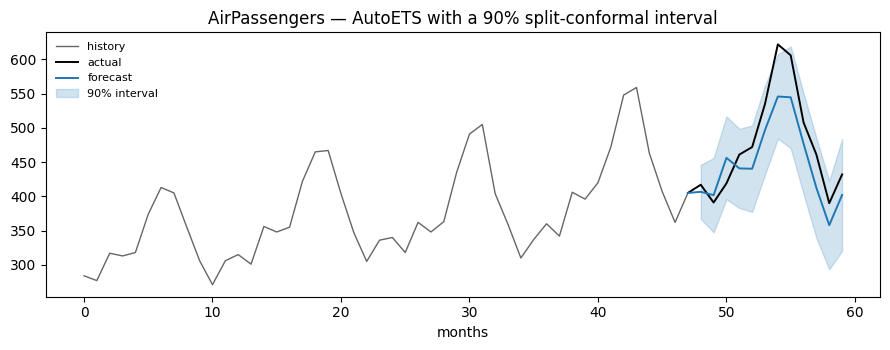

In [ ]:
def plot_interval(ax, history, actual, point, interval, *, level=90, context=48):
    """Plot the tail of a history, then a forecast with its interval.

    history  (T,)            past observations
    actual   (horizon,)      the held-out truth, or None
    point    (horizon,)      the point forecast
    interval (horizon, 2)    (lower, upper)
    """
    tail = history[-context:]
    past = np.arange(len(tail))
    future = np.arange(len(tail), len(tail) + len(point))
    # Prepend the last observation so the forecast lines join the history
    # instead of starting one step to its right.
    join = np.r_[past[-1], future]

    ax.plot(past, tail, color="0.4", lw=1, label="history")
    if actual is not None:
        ax.plot(join, np.r_[tail[-1], actual], color="k", lw=1.4, label="actual")
    ax.plot(join, np.r_[tail[-1], point], color="C0", lw=1.4, label="forecast")
    ax.fill_between(
        future,
        interval[:, 0],
        interval[:, 1],
        color="C0",
        alpha=0.2,
        label=f"{level}% interval",
    )
    return ax


fig, ax = plt.subplots(figsize=(9, 3.6))
plot_interval(
    ax,
    panel[0, :cutoff],
    panel[0, cutoff:],
    prediction.point[0, 0],
    prediction.interval[0, 0],
)
ax.set_title("AirPassengers — AutoETS with a 90% split-conformal interval")
ax.set_xlabel("months")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()

## 5. Check the coverage

An interval is only worth as much as its coverage. `evaluate` rolls the fitted
object over held-out windows and reports what fraction of actuals landed inside.

One window of 12 steps is too small to measure anything, so roll over the last
four years instead: four windows of 12 months, each predicted from the history
that precedes it.

In [ ]:
N_HOLDOUT = 4

histories, truths = [], []
for k in range(N_HOLDOUT):
    end = panel.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(panel[:, :end])
    truths.append(panel[:, end : end + HORIZON])

report = evaluate(fitted, histories, np.stack(truths, axis=1))

print(f"target coverage   {1 - report.alpha:.0%}")
print(f"measured coverage {report.marginal_coverage:.1%}")
print(f"mean width        {report.mean_interval_width:.1f} passengers")

target coverage   90%
measured coverage 93.8%
mean width        128.2 passengers


::: {.callout-warning}
## Marginal is not conditional

Conformal coverage is a guarantee *on average* over draws, not a promise about
any one cell. Coverage averaged over series and horizons can sit at 90% while a
particular horizon step is systematically under-covered — which is exactly what
`coverage_by_horizon` and `coverage_by_series` are for. AirPassengers also has a
strong upward trend, so the exchangeability that split conformal assumes is only
approximately true here; the [adaptive methods](../methods/index.html) exist for
precisely that reason.
:::

In [ ]:
print(report.summary())

Report — SplitConformal
  target coverage: 0.900
  marginal coverage: 0.938
  coverage by horizon: [1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 0.500, 0.750, 1.000, 1.000, 1.000, 1.000]
  mean width: 128.190
  mean Winkler score: 149.198
  n_holdout_samples: 4


The per-horizon breakdown makes the point concretely: the marginal figure is
comfortably above target, but step 7 — the summer peak, where a trending series
is hardest to bound — covered only half its windows. A single number would have
hidden that.

## Next

- [Methods](../methods/index.html) — the six methods, what each one is for, and when
  split conformal is not enough.
- [Diagnostics](../capabilities/diagnostics.html) — measuring an interval properly.
- [Adapters](../adapters/index.html) — mlforecast, neuralforecast, or your own model.
- [Architecture](../concepts/architecture.html) — the method as configuration, and
  the fitted object it returns.